# Employment — A Rate That Falls for Two Opposite Reasons

**Artifact class:** `tutorial`  ·  **Data mode:** `empirical`  ·  **Vintage:** ACS 2023 5-Year (pinned); BLS LAUS 2019–2024 annual (NOT pinned — no as-of)

The first notebook in this corpus built on a publisher other than the Census Bureau, and almost
everything the previous six established has to be re-derived rather than carried over.

**There are no margins of error here.** ACS publishes one for every estimate; BLS LAUS publishes
none, because sub-state LAUS figures are not survey tabulations at all — they are output from a
state-space model, and county figures are then *controlled to sum* to the state figure. Both of
those facts are checkable from the data, and both are checked below.

**And the headline statistic is ambiguous by construction.** The unemployment rate is a ratio whose
numerator and denominator both move. It falls when people find work. It also falls when people stop
looking, which removes them from both. Over 2019–2024 the correlation between a state's change in
unemployment rate and its change in employment is **+0.053** — the rate, on its own, carries almost
no information about whether more people are working.

Real data only. No synthetic fallback. *Proprietary. SPDX-License-Identifier: LicenseRef-Proprietary*

## Learning Objectives

1. **Verify** a published accounting identity rather than assuming it, and use it to establish what
   a rate's numerator and denominator actually are.
2. **Decompose** a change in a ratio into movement of its numerator and its denominator, and
   identify the cases where they imply opposite conclusions.
3. **Recognise** model-based small-area estimates: what "controlled to the state total" means, how
   to test for it, and why it makes sub-state figures non-independent.
4. **Work without margins of error** — state what cannot be concluded when the publisher supplies no
   uncertainty at all, rather than silently treating point estimates as exact.
5. **Reconcile two publishers** measuring the same concept, and test a specific hypothesis for why
   they differ rather than reporting the discrepancy as a curiosity.
6. **Choose** between two defensible published figures on the basis of the question being asked.

## Prerequisites

**Knowledge.** D01 and D03 (ACS estimates and their margins). The contrast with a publisher that
issues no margins is the point, so that background is load-bearing here.

**Setup.** `CENSUS_API_KEY` and `BLS_API_KEY` in the environment or in the file `KRL_SECRETS_PATH`
points at. The data layer refuses every credential name outside its four-key allowlist before it
opens the file.

**Packages.** `pandas`, `numpy`, `matplotlib`, and `krl_tutorials_data`.

## Data Provenance

**BLS Local Area Unemployment Statistics (LAUS)**, annual averages 2019–2024, via the BLS
timeseries API v2.

| Series pattern | Measure |
|---|---|
| `LAUST{ss}00000000000 4` | unemployment (level) |
| `LAUST{ss}00000000000 5` | employment (level) |
| `LAUST{ss}00000000000 6` | civilian labour force (level) |
| `LAUCN{sscc}00000000 5` / `…6` | the same, by county |

LAUS identifiers encode geography and measure **positionally**. That is the shape of audit finding
F-13, where a variable was assumed from its position and meant something else, so every identifier
is constructed from named parts and carries a written label into provenance.

**ACS 2023 5-Year** table `B23025`: `_003E` civilian labour force, `_005E` unemployed, with the
`…M` margins.

### Two things about LAUS that change how it may be used

**It is model output.** State LAUS estimates come from a signal-plus-noise state-space model that
combines the Current Population Survey with payroll employment and unemployment-insurance claims.
Sub-state estimates are built separately and then **benchmarked** so they sum to the state. They are
therefore not independent observations of independent places, and nothing resembling a sampling
margin is published for them.

**The API signals failure with HTTP 200.** A rejected request returns status `REQUEST_NOT_PROCESSED`
in a 200 body. Checking the status code alone would accept an error payload as data — the same trap
as the Census HTML masquerade, in a different costume. `fetch_bls` checks the status field.

In [1]:
"""Configuration. Series identifiers are built from named parts, never typed literally."""
from __future__ import annotations

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

_here = Path.cwd().resolve()
for _cand in (_here, *_here.parents):
    if (_cand / "src" / "krl_tutorials_data").is_dir():
        sys.path.insert(0, str(_cand / "src")); break
else:
    raise SystemExit("Could not locate krl_tutorials_data from " + str(_here))

from krl_tutorials_data.sources import verify_digest, fetch_acs, fetch_bls, DataAccessError
from krl_tutorials_data.uncertainty import Estimate, proportion_moe

ACS_VINTAGE = 2023
YEAR_START, YEAR_END = 2019, 2024
BENCHMARK_STATE = "51"          # Virginia, for the county-control check

# LAUS measure codes. Written out because the identifier encodes them
# positionally and an off-by-one here is invisible in the response.
LAUS_MEASURES = {
    "04": "unemployment (level)",
    "05": "employment (level)",
    "06": "civilian labour force (level)",
}
LAUS_ANNUAL = "M13"             # BLS writes the annual average as a 13th period

# Puerto Rico is excluded: its labour-force programme differs from the state
# LAUS models and mixing it into a 51-unit comparison is not like-for-like.
EXCLUDE_FIPS = {"72"}


def laus_state_series(state_fips: str, measure: str) -> str:
    return f"LAUST{state_fips}00000000000{measure}"


def laus_county_series(county_fips: str, measure: str) -> str:
    return f"LAUCN{county_fips}00000000{measure}"


pd.set_option("display.width", 150)
plt.rcParams["figure.dpi"] = 110

print(f"LAUS window     : {YEAR_START}-{YEAR_END} annual averages (period {LAUS_ANNUAL})")
print(f"ACS vintage     : {ACS_VINTAGE} 5-Year")
print(f"LAUS measures   : {len(LAUS_MEASURES)}")
for _c, _l in LAUS_MEASURES.items():
    print(f"  {_c}  {_l}")
print(f"Example series  : {laus_state_series('51', '05')}  (Virginia, employment)")
print(f"Benchmark check : state {BENCHMARK_STATE} counties vs the state total")

#: BLS LAUS is annually benchmarked and the v2 API has no as-of argument, so
#: the year range names a reference period. These pins do not restore a
#: vintage -- they guarantee a benchmark revision raises here rather than
#: moving every figure below under unchanged prose.
PINNED_LAUS_STATE = "377d223fd65179d75b6b6aae06416cdbaa93acf8b6321fd17729d326156a155f"
PINNED_LAUS_COUNTY = "3d1d9c92ff23284da9cf9a75b182a44da7fa5504104d794cf346af05092cbbaa"


LAUS window     : 2019-2024 annual averages (period M13)
ACS vintage     : 2023 5-Year
LAUS measures   : 3
  04  unemployment (level)
  05  employment (level)
  06  civilian labour force (level)
Example series  : LAUST510000000000005  (Virginia, employment)
Benchmark check : state 51 counties vs the state total


In [2]:
try:
    acs, prov_acs = fetch_acs(
        year=ACS_VINTAGE,
        variables={
            "B23025_003E": "Estimate!!In labor force:!!Civilian labor force:",
            "B23025_005E": "Estimate!!In labor force:!!Civilian labor force:!!Unemployed",
            "B23025_003M": "Margin of Error!!In labor force:!!Civilian labor force:",
            "B23025_005M": ("Margin of Error!!In labor force:!!Civilian labor "
                            "force:!!Unemployed"),
        },
        geography="state:*",
    )
    acs["fips"] = acs.state.astype(str).str.zfill(2)
    acs = acs.loc[~acs.fips.isin(EXCLUDE_FIPS)].copy()

    state_series = {
        laus_state_series(f, m): f"{n} - {lab}"
        for f, n in zip(acs.fips, acs.NAME)
        for m, lab in LAUS_MEASURES.items()
    }
    laus, prov_laus = verify_digest(
        fetch_bls(series=state_series, start_year=YEAR_START, end_year=YEAR_END),
        PINNED_LAUS_STATE, label="BLS LAUS, states",
    )
except DataAccessError as exc:
    print("HALTED - real data could not be obtained.")
    print(f"  failure class : {type(exc).__name__}")
    print(f"  detail        : {exc}")
    print("\nNo synthetic fallback exists by design.")
    raise

annual = laus.loc[laus.period == LAUS_ANNUAL].copy()
annual["fips"] = annual.series_id.str[5:7]
annual["measure"] = annual.series_id.str[-2:]
wide = (annual.pivot_table(index=["fips", "year"], columns="measure", values="value")
        .rename(columns={"04": "unemployed", "05": "employed", "06": "labour_force"})
        .reset_index())
wide.columns.name = None

print(f"States requested : {len(acs)}")
print(f"Series requested : {len(state_series)}")
print(f"State-years      : {len(wide)}")
print()
print(prov_laus.render())

States requested : 51
Series requested : 153
State-years      : 306

Source      : U.S. Bureau of Labor Statistics - BLS timeseries API v2
Vintage     : 2019 to 2024  (pinned)
Endpoint    : https://api.bls.gov/publicAPI/v2/timeseries/data/
Retrieved   : 2026-09-18T12:42:14+00:00
Shape       : 11934 rows x 7 cols
Payload hash: 377d223fd65179d7...  (canonical-stable-json)
Data mode   : EMPIRICAL
Variables   :
              LAUST010000000000004 Alabama - unemployment (level)
              LAUST010000000000005 Alabama - employment (level)
              LAUST010000000000006 Alabama - civilian labour force (level)
              LAUST020000000000004 Alaska - unemployment (level)
              LAUST020000000000005 Alaska - employment (level)
              LAUST020000000000006 Alaska - civilian labour force (level)
              LAUST040000000000004 Arizona - unemployment (level)
              LAUST040000000000005 Arizona - employment (level)
              LAUST040000000000006 Arizona - civilia

## 1. The identity, checked rather than assumed

The unemployment rate is `unemployed / labour force`, and the labour force is by definition
`employed + unemployed`. That is an accounting identity, not an estimate — but the three series are
published separately, so whether they actually reconcile is a fact about the data rather than about
the definition.

In [3]:
residual = (wide.unemployed + wide.employed - wide.labour_force).abs()
exact = int((residual < 0.5).sum())
print(f"unemployed + employed == labour force")
print(f"  exact in {exact} of {len(wide)} state-years")
print(f"  largest deviation: {residual.max():.1f} persons")
if exact != len(wide):
    print("\nState-years that do not reconcile:")
    print(wide.loc[residual >= 0.5].to_string(index=False))
    raise SystemExit(
        "The published components do not sum. Stop before computing any rate from them."
    )

wide["rate"] = wide.unemployed / wide.labour_force
print()
print(f"Unemployment rate, {YEAR_END}: median {wide.loc[wide.year == YEAR_END, 'rate'].median():.3%}, "
      f"range {wide.loc[wide.year == YEAR_END, 'rate'].min():.3%} to "
      f"{wide.loc[wide.year == YEAR_END, 'rate'].max():.3%}")
print("The identity holding exactly is itself evidence of the method: these are not three")
print("independent measurements that happen to agree, they are a modelled set constrained")
print("to be internally consistent.")

unemployed + employed == labour force
  exact in 306 of 306 state-years
  largest deviation: 0.0 persons

Unemployment rate, 2024: median 3.656%, range 1.824% to 5.394%
The identity holding exactly is itself evidence of the method: these are not three
independent measurements that happen to agree, they are a modelled set constrained
to be internally consistent.


## 2. A rate that falls for two opposite reasons

$$\text{rate} = \frac{U}{U + E}$$

The rate falls when $U$ falls because people found work, and it falls when $U$ falls because people
stopped looking — a person who stops searching leaves $U$ *and* leaves the labour force entirely.
The two cases are indistinguishable in the rate and are distinguished immediately by looking at
whether $E$ rose or fell.

In [4]:
ends = wide.loc[wide.year.isin([YEAR_START, YEAR_END])]
panel = ends.pivot(index="fips", columns="year",
                   values=["unemployed", "employed", "labour_force", "rate"])
panel.columns = [f"{a}_{b}" for a, b in panel.columns]
panel = panel.dropna().join(acs.set_index("fips")[["NAME"]])

panel["d_rate_pp"] = (panel[f"rate_{YEAR_END}"] - panel[f"rate_{YEAR_START}"]) * 100
panel["d_employed"] = panel[f"employed_{YEAR_END}"] / panel[f"employed_{YEAR_START}"] - 1
panel["d_labour_force"] = (panel[f"labour_force_{YEAR_END}"]
                           / panel[f"labour_force_{YEAR_START}"] - 1)

fell = panel.d_rate_pp < 0
exited = fell & (panel.d_employed < 0)
grew = fell & (panel.d_employed > 0)

print(f"{YEAR_START} to {YEAR_END}, {len(panel)} states")
print(f"  unemployment rate fell in                        {int(fell.sum()):>3}")
print(f"    ...with employment ALSO falling (exit)         {int(exited.sum()):>3}")
print(f"    ...with employment growing (genuine gain)      {int(grew.sum()):>3}")
print()
print(f"  correlation, change in rate vs change in employment: "
      f"{np.corrcoef(panel.d_rate_pp, panel.d_employed)[0, 1]:+.3f}")
print()
if int(exited.sum()):
    print("States where the rate improved while employment shrank:")
    for _, r in panel.loc[exited].sort_values("d_rate_pp").iterrows():
        print(f"  {r.NAME:<24} rate {r.d_rate_pp:+.2f} pp | employment "
              f"{r.d_employed:+.2%} | labour force {r.d_labour_force:+.2%}")
print()
print("A near-zero correlation is the finding. Over this window a state's change in")
print("unemployment rate carries almost no information about whether more of its people")
print("are working, which is the question the rate is usually quoted to answer.")

2019 to 2024, 51 states
  unemployment rate fell in                         19
    ...with employment ALSO falling (exit)           2
    ...with employment growing (genuine gain)       17

  correlation, change in rate vs change in employment: +0.053

States where the rate improved while employment shrank:
  Louisiana                rate -0.35 pp | employment -0.13% | labour force -0.50%
  Maryland                 rate -0.20 pp | employment -2.60% | labour force -2.81%

A near-zero correlation is the finding. Over this window a state's change in
unemployment rate carries almost no information about whether more of its people
are working, which is the question the rate is usually quoted to answer.


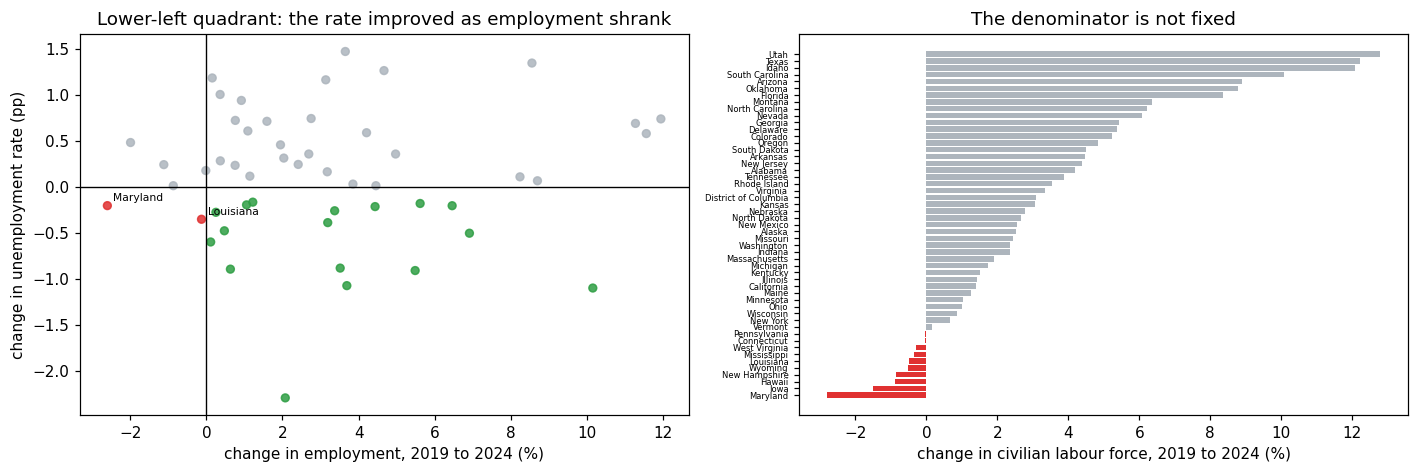

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))

colour = np.where(exited, "#e03131", np.where(grew, "#2f9e44", "#adb5bd"))
axes[0].scatter(panel.d_employed * 100, panel.d_rate_pp, s=26, c=colour, alpha=.85)
axes[0].axhline(0, color="k", lw=.9); axes[0].axvline(0, color="k", lw=.9)
axes[0].set_xlabel(f"change in employment, {YEAR_START} to {YEAR_END} (%)")
axes[0].set_ylabel("change in unemployment rate (pp)")
axes[0].set_title("Lower-left quadrant: the rate improved as employment shrank")
for _, r in panel.loc[exited].iterrows():
    axes[0].annotate(r.NAME, (r.d_employed * 100, r.d_rate_pp),
                     fontsize=7, xytext=(4, 3), textcoords="offset points")

order = panel.sort_values("d_labour_force")
axes[1].barh(range(len(order)), order.d_labour_force * 100,
             color=np.where(order.d_labour_force < 0, "#e03131", "#adb5bd"))
axes[1].set_yticks(range(len(order)))
axes[1].set_yticklabels(order.NAME, fontsize=5.5)
axes[1].set_xlabel(f"change in civilian labour force, {YEAR_START} to {YEAR_END} (%)")
axes[1].set_title("The denominator is not fixed")
plt.tight_layout(); plt.show()

## 3. County figures are controlled to the state total

LAUS sub-state estimates are benchmarked: they are adjusted so that the counties within a state sum
to the state's own model estimate. That has a direct analytical consequence — county figures are not
independent observations, so treating them as independent draws (for a variance, a regression
standard error, or a significance test between two counties) misstates what the data can support.

The claim is testable in one line.

In [6]:
try:
    counties, _prov_c = fetch_acs(
        year=ACS_VINTAGE, variables={"B23025_001E": "Estimate!!Total: (population 16+)"},
        geography="county:*", within=f"state:{BENCHMARK_STATE}",
    )
except DataAccessError as exc:
    print(f"HALTED - {type(exc).__name__}: {exc}")
    raise

county_fips = sorted(
    (counties.state.astype(str).str.zfill(2) + counties.county.astype(str).str.zfill(3)).unique()
)
county_series = {
    laus_county_series(c, m): f"county {c} - {lab}"
    for c in county_fips for m, lab in LAUS_MEASURES.items() if m != "04"
}
county_laus, prov_county = verify_digest(
    fetch_bls(series=county_series, start_year=YEAR_END, end_year=YEAR_END),
    PINNED_LAUS_COUNTY, label="BLS LAUS, counties",
)
ca = county_laus.loc[county_laus.period == LAUS_ANNUAL].copy()
ca["measure"] = ca.series_id.str[-2:]
county_totals = ca.groupby("measure").value.sum()

state_row = wide.loc[(wide.fips == BENCHMARK_STATE) & (wide.year == YEAR_END)].iloc[0]
state_name = acs.loc[acs.fips == BENCHMARK_STATE, "NAME"].iloc[0]

print(f"{state_name}, {YEAR_END}: {len(county_fips)} counties and independent cities")
print(f"{'measure':<24}{'county sum':>14}{'state model':>14}{'difference':>12}{'as % of state':>15}")
for m, col in (("05", "employed"), ("06", "labour_force")):
    csum, sval = county_totals[m], state_row[col]
    print(f"  {LAUS_MEASURES[m]:<22}{csum:>14,.0f}{sval:>14,.0f}"
          f"{csum - sval:>+12,.0f}{(csum - sval) / sval:>14.5%}")
print()
print("The county figures reproduce the state total to rounding. They are constrained to,")
print("by construction. Two consequences follow: a county is not an independent observation,")
print("and a county's estimate can move because its own conditions changed or because the")
print("state control it is fitted to moved.")

Virginia, 2024: 133 counties and independent cities
measure                     county sum   state model  difference  as % of state
  employment (level)         4,419,521     4,419,514          +7      0.00016%
  civilian labour force (level)     4,552,298     4,552,283         +15      0.00033%

The county figures reproduce the state total to rounding. They are constrained to,
by construction. Two consequences follow: a county is not an independent observation,
and a county's estimate can move because its own conditions changed or because the
state control it is fitted to moved.


## 4. Two publishers, one concept, and a testable explanation

The Census Bureau also publishes a state unemployment rate, from the ACS, with a margin of error.
BLS publishes one from LAUS, with none. They do not agree.

A discrepancy is only interesting if it is explained, so a specific hypothesis is tested: **the ACS
5-year figure is a 2019–2023 period average and the LAUS figure is a single calendar year.** If that
is the cause, averaging LAUS over the same five years should close most of the gap.

In [7]:
acs_rate = acs.assign(
    clf=pd.to_numeric(acs.B23025_003E, errors="coerce"),
    unemployed=pd.to_numeric(acs.B23025_005E, errors="coerce"),
)
acs_rate["acs_rate"] = acs_rate.unemployed / acs_rate.clf
acs_rate["acs_moe"] = [
    proportion_moe(Estimate(u, um), Estimate(l, lm))
    for u, um, l, lm in zip(
        acs_rate.unemployed, pd.to_numeric(acs_rate.B23025_005M, errors="coerce"),
        acs_rate.clf, pd.to_numeric(acs_rate.B23025_003M, errors="coerce"))
]

single = wide.loc[wide.year == ACS_VINTAGE, ["fips", "rate"]].rename(
    columns={"rate": "laus_single_year"})
window = (wide.loc[wide.year.between(ACS_VINTAGE - 4, ACS_VINTAGE)]
          .groupby("fips")
          .apply(lambda g: g.unemployed.sum() / g.labour_force.sum(), include_groups=False)
          .rename("laus_five_year").reset_index())

cmp = (acs_rate[["fips", "NAME", "acs_rate", "acs_moe"]]
       .merge(single, on="fips").merge(window, on="fips"))
cmp["gap_single_pp"] = (cmp.acs_rate - cmp.laus_single_year) * 100
cmp["gap_window_pp"] = (cmp.acs_rate - cmp.laus_five_year) * 100

print(f"State unemployment rate, {len(cmp)} states")
print(f"  ACS {ACS_VINTAGE} 5-Year          median {cmp.acs_rate.median():.3%}   "
      f"median published margin {cmp.acs_moe.median() * 100:.3f} pp")
print(f"  LAUS {ACS_VINTAGE} annual         median {cmp.laus_single_year.median():.3%}   "
      f"published margin: none")
print(f"  LAUS {ACS_VINTAGE - 4}-{ACS_VINTAGE} pooled      median "
      f"{cmp.laus_five_year.median():.3%}")
print()
print(f"  ACS minus LAUS single year : median {cmp.gap_single_pp.median():+.2f} pp, "
      f"mean |gap| {cmp.gap_single_pp.abs().mean():.2f} pp")
print(f"  ACS minus LAUS five year   : median {cmp.gap_window_pp.median():+.2f} pp, "
      f"mean |gap| {cmp.gap_window_pp.abs().mean():.2f} pp")
_closed = 1 - cmp.gap_window_pp.abs().mean() / cmp.gap_single_pp.abs().mean()
print(f"  matching the reference period closes {_closed:.0%} of the average gap")
print()
_beyond = int((cmp.gap_single_pp.abs() / 100 > cmp.acs_moe).sum())
print(f"  states whose single-year gap exceeds the ACS 90% margin: {_beyond} of {len(cmp)}")
print(f"  states whose period-matched gap still exceeds it       : "
      f"{int((cmp.gap_window_pp.abs() / 100 > cmp.acs_moe).sum())} of {len(cmp)}")
r_acs = cmp.acs_rate.rank(ascending=False, method="first")
r_laus = cmp.laus_single_year.rank(ascending=False, method="first")
print()
print(f"  rank disagreement, ACS vs LAUS single year: largest move "
      f"{int((r_acs - r_laus).abs().max())} places, "
      f"{int((r_acs - r_laus).abs().ge(5).sum())} states move 5+")
print(f"  correlation: {np.corrcoef(cmp.acs_rate, cmp.laus_single_year)[0, 1]:.4f}")

State unemployment rate, 51 states
  ACS 2023 5-Year          median 4.938%   median published margin 0.133 pp
  LAUS 2023 annual         median 3.203%   published margin: none
  LAUS 2019-2023 pooled      median 4.361%

  ACS minus LAUS single year : median +1.49 pp, mean |gap| 1.51 pp
  ACS minus LAUS five year   : median +0.27 pp, mean |gap| 0.42 pp
  matching the reference period closes 72% of the average gap

  states whose single-year gap exceeds the ACS 90% margin: 51 of 51
  states whose period-matched gap still exceeds it       : 40 of 51

  rank disagreement, ACS vs LAUS single year: largest move 23 places, 30 states move 5+
  correlation: 0.7938


## Limitations

- **LAUS publishes no measure of uncertainty**, so nothing in this notebook can say whether two
  states' LAUS rates are distinguishable. That is not a gap this analysis can fill by computing
  something; the publisher does not provide the input.
- **LAUS sub-state estimates are model output controlled to a state total.** They are not
  independent observations, so variance estimates, regression standard errors and pairwise tests
  across counties are not supported by the data as published.
- **LAUS is revised annually.** Each benchmarking cycle rewrites history; figures retrieved on a
  later date will differ from these. The retrieval date is in the provenance record for that reason.
- **The unemployment rate excludes discouraged workers by construction.** Someone who has stopped
  searching is in neither the numerator nor the denominator. The labour-force participation rate and
  the employment-population ratio answer different questions and are not computed here.
- **ACS and LAUS use different universes and reference periods.** The period-matched test above
  addresses the reference period only; definitional and methodological differences remain and are
  not separated.
- **Puerto Rico is excluded** as not like-for-like with the state LAUS models.
- **Two endpoint years are compared.** A state that moved sharply between them is described by the
  endpoints alone, and nothing here identifies why any series moved.

In [8]:
"""Findings. Every number below is rendered from a value computed above."""
print("FINDINGS")
print("=" * 78)
print(f"1. The published components reconcile exactly: unemployed + employed == labour force")
print(f"   in {exact} of {len(wide)} state-years, largest deviation {residual.max():.1f} persons.")
print(f"   That is a property of a constrained model, not agreement between measurements.")
print(f"2. {YEAR_START} to {YEAR_END}: the unemployment rate fell in {int(fell.sum())} states. "
      f"In {int(exited.sum())} of those, employment")
print(f"   fell too - the rate improved because people left the labour force.")
print(f"3. Correlation between change in unemployment rate and change in employment: "
      f"{np.corrcoef(panel.d_rate_pp, panel.d_employed)[0, 1]:+.3f}.")
print(f"   The rate alone is close to uninformative about whether more people are working.")
print(f"4. {state_name}'s {len(county_fips)} counties sum to the state employment total to within")
print(f"   {abs(county_totals['05'] - state_row.employed):,.0f} persons "
      f"({abs(county_totals['05'] - state_row.employed) / state_row.employed:.5%}). County figures "
      f"are controlled to the state,")
print(f"   so they are not independent observations.")
print(f"5. ACS and LAUS disagree by a median {cmp.gap_single_pp.median():+.2f} pp, and "
      f"{_beyond} of {len(cmp)} states differ by more")
print(f"   than the ACS margin - the gap is not sampling noise. Matching the reference period")
print(f"   closes {_closed:.0%} of it, which supports the 5-year-window explanation.")
print(f"6. ACS publishes a median margin of {cmp.acs_moe.median() * 100:.3f} pp on this quantity. "
      f"LAUS publishes none.")
print("=" * 78)

FINDINGS
1. The published components reconcile exactly: unemployed + employed == labour force
   in 306 of 306 state-years, largest deviation 0.0 persons.
   That is a property of a constrained model, not agreement between measurements.
2. 2019 to 2024: the unemployment rate fell in 19 states. In 2 of those, employment
   fell too - the rate improved because people left the labour force.
3. Correlation between change in unemployment rate and change in employment: +0.053.
   The rate alone is close to uninformative about whether more people are working.
4. Virginia's 133 counties sum to the state employment total to within
   7 persons (0.00016%). County figures are controlled to the state,
   so they are not independent observations.
5. ACS and LAUS disagree by a median +1.49 pp, and 51 of 51 states differ by more
   than the ACS margin - the gap is not sampling noise. Matching the reference period
   closes 72% of it, which supports the 5-year-window explanation.
6. ACS publishes a me

## Key Takeaways

1. Check a published identity before computing from its parts. Here it holds exactly, and that
   exactness is itself information: these are constrained model outputs, not independent readings.
2. A ratio can move because of its numerator or its denominator, and for the unemployment rate those
   two cases carry opposite meanings. Report the employment level alongside the rate, always.
3. "Model-based, controlled to a higher-level total" is a property with analytical consequences.
   Sub-state figures built that way are not independent, and the usual tools that assume independence
   do not apply.
4. When a publisher issues no uncertainty, say so and stop. Do not substitute a computed interval
   that implies a sampling design the estimate does not have.
5. Two defensible published figures for the same concept can differ by more than either one's stated
   precision. Before choosing, form a hypothesis about why and test it — here, matching the reference
   period accounts for most of the gap.
6. Choose the source by the question. A single calendar year for "what happened last year"; a
   pooled multi-year estimate for a small area or a stable structural picture.

## Exercises

1. **The measures the rate hides.** Compute the labour-force participation rate and the
   employment-population ratio from LAUS and ACS `B23025`. Do the states flagged here as
   labour-force exit look different on those, and would they have been visible without the
   decomposition?
2. **County independence, tested.** Take a second state's counties and regress county rate on a
   county characteristic. Then repeat within a single state after removing the state mean. How much
   of the apparent cross-county variation survives once the shared state control is removed?
3. **Revision size.** LAUS is re-benchmarked annually. Retrieve the same series again in six months
   and quantify how far the 2024 annual averages moved. Does any conclusion above change?
4. **Monthly instead of annual.** Re-run the decomposition on monthly data. Does the seasonal
   pattern change which states appear to be shedding labour force?
5. **Close the remaining gap.** The period-matched test leaves some ACS–LAUS difference unexplained.
   Test a second hypothesis — the ACS universe is residence-based and includes people the CPS
   definition treats differently — and quantify what it accounts for.
6. **A margin where none is published.** BLS documents the LAUS model. Read the methodology and
   state precisely what would be needed to attach an interval to a county estimate, and why the
   Bureau does not publish one.

## References

- U.S. Bureau of Labor Statistics. *Local Area Unemployment Statistics: Estimation Methodology* —
  the state-space models, and the benchmarking of sub-state estimates to state controls.
  <https://www.bls.gov/lau/laumthd.htm>
- U.S. Bureau of Labor Statistics. *BLS Public Data API, Version 2*.
  <https://www.bls.gov/developers/api_signature_v2.htm>
- U.S. Bureau of Labor Statistics. *How the Government Measures Unemployment* — the labour-force
  definitions, including discouraged workers and marginal attachment.
- U.S. Census Bureau. *American Community Survey 2023 5-Year Estimates*, table **B23025**.
- U.S. Census Bureau and BLS. *Comparing ACS and CPS/LAUS labor force estimates* — reference period
  and universe differences between the two programmes.
- Tiller, R. B. (1992). "Time Series Modeling of Sample Survey Data from the U.S. Current Population
  Survey." *Journal of Official Statistics* 8(2), 149–166 — the signal-plus-noise approach
  underlying LAUS.

In [9]:
"""Provenance for all sources, written beside the notebook."""
#: The repository root, found by walking UP from wherever this runs. Provenance
#: used to be written to `Path.cwd() / "provenance"` in some notebooks and to a
#: repo-root-relative path in others, so the two conventions could not both be
#: satisfied by one working directory -- and a run from the wrong one silently
#: wrote sixteen records into a stray folder at the top of the repo.
REPO_ROOT = next(c for c in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                 if (c / "src" / "krl_tutorials_data").is_dir())
out_dir = REPO_ROOT / "projects" / "01-fundamentals/D02_employment_and_labor" / "provenance"
written = [
    prov_laus.write(out_dir / "d02_bls_laus_state.json"),
    prov_county.write(out_dir / "d02_bls_laus_county.json"),
    prov_acs.write(out_dir / "d02_acs_b23025_state.json"),
]
print("Provenance written:")
for p in written:
    print(f"  {p.name}")
print()
print(f"LAUS state digest  : {prov_laus.content_sha256[:16]}...")
print(f"LAUS county digest : {prov_county.content_sha256[:16]}...")
print(f"ACS digest         : {prov_acs.content_sha256[:16]}...")
print()
print(f"States             : {len(panel)}")
print(f"Window             : {YEAR_START}-{YEAR_END} annual averages")
print(f"Uncertainty        : ACS margins used; LAUS publishes none")

Provenance written:
  d02_bls_laus_state.json
  d02_bls_laus_county.json
  d02_acs_b23025_state.json

LAUS state digest  : 377d223fd65179d7...
LAUS county digest : 3d1d9c92ff23284d...
ACS digest         : 506894c0d0b24348...

States             : 51
Window             : 2019-2024 annual averages
Uncertainty        : ACS margins used; LAUS publishes none
